In [1]:
import kagglehub
from pathlib import Path
import pandas as pd

# Download latest version
path = Path(kagglehub.dataset_download("zynicide/wine-reviews"))
INPUT_FILE = path / "winemag-data-130k-v2.csv"

print("Dataset directory:", path)
print("Path to dataset file:", INPUT_FILE)

wines = pd.read_csv(INPUT_FILE, index_col=0)

print("Dataset shape:", wines.shape)
display(wines.head())

Using Colab cache for faster access to the 'wine-reviews' dataset.
Dataset directory: /kaggle/input/wine-reviews
Path to dataset file: /kaggle/input/wine-reviews/winemag-data-130k-v2.csv
Dataset shape: (129971, 13)


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [2]:
data = wines[["taster_name", "description"]].dropna().copy()
data["description"] = data["description"].astype(str).str.strip()
data = data[data["description"] != ""]

# Normalize case and whitespace only for duplicate detection
data["_text_key"] = (
    data["description"]
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Exclude identical wording assigned to multiple reviewers
reviewer_count_per_text = data.groupby("_text_key")["taster_name"].transform("nunique")
data = data[reviewer_count_per_text == 1]

# Keep one instance of each review
data = data.drop_duplicates(subset="_text_key")

# Keep reviewers with at least 100 unique reviews
reviewer_counts = data["taster_name"].value_counts()
eligible_reviewers = reviewer_counts[reviewer_counts >= 100].index
data = data[data["taster_name"].isin(eligible_reviewers)].copy()

print("Reviewers included:", len(eligible_reviewers))
print("Unique reviews used:", len(data))
display(data["taster_name"].value_counts().rename("reviews"))

Reviewers included: 17
Unique reviews used: 95011


,reviews
taster_name,
Roger Voss,23558
Michael Schachner,14045
Kerin O’Keefe,9679
Paul Gregutt,8867
Virginie Boone,8707
Matt Kettmann,5729
Joe Czerwinski,4763
Sean P. Sullivan,4460
Anna Lee C. Iijima,4017


In [3]:
from sklearn.model_selection import train_test_split

# Hold out test data for the final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    data["description"],
    data["taster_name"],
    test_size=0.2,
    random_state=42,
    stratify=data["taster_name"]
)

# Set aside validation data from the training split for early stopping
X_fit_text, X_val_text, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=43,
    stratify=y_train
)

print("Fit reviews:", len(X_fit_text))
print("Validation reviews:", len(X_val_text))
print("Test reviews:", len(X_test))

Fit reviews: 64606
Validation reviews: 11402
Test reviews: 19003


In [8]:
import numpy as np
import torch
import torch.nn.functional as F

from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# Character patterns capture spelling, punctuation, and word fragments
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=10,
    max_features=20_000,
    lowercase=False,
    dtype=np.float32
)

# Fit vocabulary on fit text only
X_fit_tfidf = vectorizer.fit_transform(X_fit_text)
X_val_tfidf = vectorizer.transform(X_val_text)
X_test_tfidf = vectorizer.transform(X_test)

# Convert reviewer names to numeric class IDs
label_encoder = LabelEncoder().fit(y_fit)
y_fit_ids = label_encoder.transform(y_fit)
y_val_ids = label_encoder.transform(y_val)

# Convert SciPy matrices to PyTorch sparse CSR tensors
def to_torch_csr(matrix):
    matrix = matrix.tocsr().astype(np.float32)

    crow_indices = torch.tensor(
        matrix.indptr.astype(np.int64),
        dtype=torch.long,
        device=device
    )
    col_indices = torch.tensor(
        matrix.indices.astype(np.int64),
        dtype=torch.long,
        device=device
    )
    values = torch.tensor(
        matrix.data,
        dtype=torch.float32,
        device=device
    )

    return torch.sparse_csr_tensor(
        crow_indices,
        col_indices,
        values,
        size=matrix.shape,
        device=device
    )

X_fit_torch = to_torch_csr(X_fit_tfidf)
X_val_torch = to_torch_csr(X_val_tfidf)
X_test_torch = to_torch_csr(X_test_tfidf)

y_fit_torch = torch.tensor(y_fit_ids, dtype=torch.long, device=device)
y_val_torch = torch.tensor(y_val_ids, dtype=torch.long, device=device)

n_features = X_fit_tfidf.shape[1]
n_classes = len(label_encoder.classes_)

print("Character features:", n_features)
print("Reviewer classes:", n_classes)

Using: cuda
Character features: 20000
Reviewer classes: 17


In [9]:
def soft_macro_f1(logits, labels):
    probabilities = torch.softmax(logits, dim=1)
    targets = F.one_hot(labels, num_classes=n_classes).float()

    true_positives = (probabilities * targets).sum(dim=0)
    false_positives = (probabilities * (1 - targets)).sum(dim=0)
    false_negatives = ((1 - probabilities) * targets).sum(dim=0)

    f1_per_reviewer = (
        2 * true_positives
        / (
            2 * true_positives
            + false_positives
            + false_negatives
            + 1e-8
        )
    )

    return f1_per_reviewer.mean()


torch.manual_seed(42)

weights = nn.Parameter(torch.empty(n_features, n_classes, device=device))
nn.init.xavier_uniform_(weights)

bias = nn.Parameter(torch.zeros(n_classes, device=device))
optimizer = torch.optim.Adam([weights, bias], lr=0.03)

max_epochs = 250
patience = 20
min_improvement = 1e-4

best_val_f1 = -float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_weights = None
best_bias = None

for epoch in range(1, max_epochs + 1):
    # Train using soft macro-F1 loss
    optimizer.zero_grad()

    fit_logits = torch.sparse.mm(X_fit_torch, weights) + bias
    loss = 1 - soft_macro_f1(fit_logits, y_fit_torch)

    loss.backward()
    optimizer.step()

    # Check validation soft macro-F1
    with torch.no_grad():
        val_logits = torch.sparse.mm(X_val_torch, weights) + bias
        val_f1 = soft_macro_f1(val_logits, y_val_torch).item()

    if val_f1 > best_val_f1 + min_improvement:
        best_val_f1 = val_f1
        best_epoch = epoch
        best_weights = weights.detach().clone()
        best_bias = bias.detach().clone()
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"loss: {loss.item():.4f} | "
            f"validation soft macro-F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"Stopping early at epoch {epoch}.")
        break

# Restore weights from the best validation epoch
with torch.no_grad():
    weights.copy_(best_weights)
    bias.copy_(best_bias)

print("Best epoch:", best_epoch)
print("Best validation soft macro-F1:", round(best_val_f1, 4))

Epoch 001 | loss: 0.9543 | validation soft macro-F1: 0.0708
Epoch 010 | loss: 0.5535 | validation soft macro-F1: 0.4758
Epoch 020 | loss: 0.2243 | validation soft macro-F1: 0.7552
Epoch 030 | loss: 0.1011 | validation soft macro-F1: 0.8442
Epoch 040 | loss: 0.0531 | validation soft macro-F1: 0.8744
Epoch 050 | loss: 0.0366 | validation soft macro-F1: 0.8866
Epoch 060 | loss: 0.0288 | validation soft macro-F1: 0.8921
Epoch 070 | loss: 0.0238 | validation soft macro-F1: 0.8961
Epoch 080 | loss: 0.0199 | validation soft macro-F1: 0.8992
Epoch 090 | loss: 0.0171 | validation soft macro-F1: 0.9023
Epoch 100 | loss: 0.0152 | validation soft macro-F1: 0.9033
Epoch 110 | loss: 0.0136 | validation soft macro-F1: 0.9036
Epoch 120 | loss: 0.0123 | validation soft macro-F1: 0.9043
Epoch 130 | loss: 0.0110 | validation soft macro-F1: 0.9060
Epoch 140 | loss: 0.0102 | validation soft macro-F1: 0.9068
Epoch 150 | loss: 0.0095 | validation soft macro-F1: 0.9073
Epoch 160 | loss: 0.0089 | validation so

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

with torch.no_grad():
    test_logits = torch.sparse.mm(X_test_torch, weights) + bias
    predicted_ids = test_logits.argmax(dim=1).cpu().numpy()

predicted_reviewers = label_encoder.inverse_transform(predicted_ids)

# Per-reviewer metrics
report = pd.DataFrame(
    classification_report(
        y_test,
        predicted_reviewers,
        output_dict=True,
        zero_division=0
    )
).T

by_reviewer = report.drop(
    index=["accuracy", "macro avg", "weighted avg"],
    errors="ignore"
).copy()

# Accuracy and weighted F1 are overall metrics, so leave them blank for individual reviewers
by_reviewer["accuracy"] = np.nan
by_reviewer["weighted_f1"] = np.nan

# Add one Overall row
overall = pd.DataFrame(
    [{
        "precision": report.loc["macro avg", "precision"],
        "recall": report.loc["macro avg", "recall"],
        "f1-score": f1_score(y_test, predicted_reviewers, average="macro"),
        "support": len(y_test),
        "accuracy": accuracy_score(y_test, predicted_reviewers),
        "weighted_f1": f1_score(y_test, predicted_reviewers, average="weighted")
    }],
    index=["Overall"]
)

results = pd.concat([
    by_reviewer.sort_values("f1-score", ascending=False),
    overall
])

display(
    results[
        ["precision", "recall", "f1-score", "support", "accuracy", "weighted_f1"]
    ].round(3)
)

,precision,recall,f1-score,support,accuracy,weighted_f1
Kerin O’Keefe,0.994,0.996,0.995,1936.0,NaN,NaN
Roger Voss,0.992,0.995,0.993,4712.0,NaN,NaN
Anna Lee C. Iijima,0.987,0.983,0.985,803.0,NaN,NaN
Sean P. Sullivan,0.989,0.980,0.984,892.0,NaN,NaN
Matt Kettmann,0.984,0.983,0.984,1146.0,NaN,NaN
Anne Krebiehl MW,0.985,0.979,0.982,658.0,NaN,NaN
Michael Schachner,0.973,0.988,0.981,2809.0,NaN,NaN
Jim Gordon,0.980,0.977,0.979,753.0,NaN,NaN
Susan Kostrzewa,1.000,0.946,0.972,204.0,NaN,NaN
Virginie Boone,0.963,0.970,0.967,1741.0,NaN,NaN


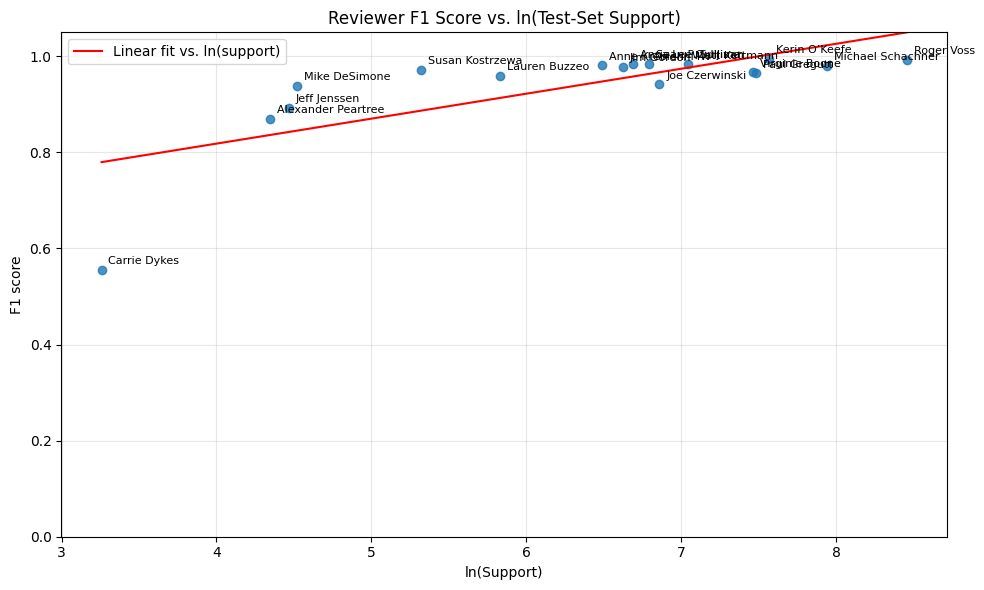

In [11]:
import matplotlib.pyplot as plt

plot_data = by_reviewer.dropna(subset=["support", "f1-score"]).copy()
plot_data = plot_data[plot_data["support"] > 0]
plot_data["ln_support"] = np.log(plot_data["support"])

# Linear fit against ln(support)
slope, intercept = np.polyfit(
    plot_data["ln_support"],
    plot_data["f1-score"],
    1
)

x_line = np.linspace(
    plot_data["ln_support"].min(),
    plot_data["ln_support"].max(),
    100
)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    plot_data["ln_support"],
    plot_data["f1-score"],
    alpha=0.8
)
ax.plot(
    x_line,
    y_line,
    color="red",
    label="Linear fit vs. ln(support)"
)

for reviewer, row in plot_data.iterrows():
    ax.annotate(
        reviewer,
        (row["ln_support"], row["f1-score"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("ln(Support)")
ax.set_ylabel("F1 score")
ax.set_title("Reviewer F1 Score vs. ln(Test-Set Support)")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()